In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import re

In [2]:
def atomic_force_analysis(dataset_file):
    # Read the dataset file
    with open(dataset_file, 'r') as file:
        lines = file.readlines()
   
    n_atom=[]
    
    H=re.compile(r"H")
    O=re.compile(r"O")
    Fe=re.compile(r"Fe")
    
    atom_count=0
    struct_count=0
   
    mean_H_forces=[]
    mean_O_forces=[]
    mean_Fe_forces=[]
    
    
    H_forces=[]
    O_forces=[]
    Fe_forces=[]
    
    H_v=[]
    H_v_tmp=[]
  
    
    
    O_v=[]
    O_v_tmp=[]
 
    
    Fe_v=[]
    Fe_v_tmp=[]

    
    
    H_tmp=[]
    O_tmp=[]
    Fe_tmp=[]
    
    for i , line in enumerate(lines):
        
        if line.startswith('atom'):
            #print(line)
            split_line=line.split()
    
            atom_count=atom_count+1
            if H.search(line):
                #print(line)
                H_tmp.append( np.sqrt(float(split_line[7])**2+ float(split_line[8])**2+ float(split_line[9])**2))
                H_v_tmp.append( [float(split_line[7]) , float(split_line[8]) , float(split_line[9])])
               
                
            if O.search(line):
                #print(line)
                O_tmp.append( np.sqrt(float(split_line[7])**2+ float(split_line[8])**2+ float(split_line[9])**2))
                O_v_tmp.append( [float(split_line[7]), float(split_line[8]), float(split_line[9])])
               
            if Fe.search(line):
                #print(line)
                Fe_tmp.append( np.sqrt(float(split_line[7])**2+ float(split_line[8])**2+ float(split_line[9])**2))
                Fe_v_tmp.append( [float(split_line[7]), float(split_line[8]) ,float(split_line[9])])
                
                
          
        if line.startswith('energy'): 
            split_line=line.split()
            #print(split_line[1])
         
            H_v.append(np.transpose(H_v_tmp))
         
            O_v.append(np.transpose(O_v_tmp))
            
          
            Fe_v.append(np.transpose(Fe_v_tmp))
            
            
            H_forces.append(H_tmp) 
            O_forces.append(O_tmp) 
            Fe_forces.append(Fe_tmp) 
            
            mean_H_forces.append(np.mean(H_tmp))
            mean_O_forces.append(np.mean(O_tmp))
            mean_Fe_forces.append(np.mean(Fe_tmp))
            
            n_atom.append(atom_count)
            struct_count=struct_count+1
            atom_count=0 
            
            H_v_tmp=[]
            O_v_tmp=[]
            Fe_v_tmp=[]
            
            H_tmp=[]
            O_tmp=[]
            Fe_tmp=[]
            
    print(dataset_file)   
    print("Total number of structures: {}".format(struct_count))     
    print(len(Fe_v[0]))
    
    Fe_v_final=Fe_v
    H_v_final=[ np.array(H_v)[:,0,:].flatten(),  np.array(H_v)[:,1,:].flatten() ,   np.array(H_v)[:,2,:].flatten() ]  
    O_v_final=[ np.array(O_v)[:,0,:].flatten(),  np.array(O_v)[:,1,:].flatten() ,   np.array(O_v)[:,2,:].flatten() ]  
    if(len(Fe_v[0])) != 0:
        Fe_v_final=[ np.array(Fe_v)[:,0,:].flatten(),  np.array(Fe_v)[:,1,:].flatten(),   np.array(Fe_v)[:,2,:].flatten() ]       

    
    
    
            
       
            
        
    
    return   np.transpose(H_forces), np.transpose(O_forces), np.transpose(Fe_forces),H_v_final, O_v_final ,Fe_v_final

In [3]:
folder_path = "./"

# Get a list of all files in the folder
all_files = os.listdir(folder_path)

# Filter files with the .data extension
data_files = [file for file in all_files if file.endswith(".data") and file.startswith("input_")]
data_files.sort()
# Loop over the .data files
for data in data_files:
    print(data)


input_111.data
input_114.data
input_126.data
input_132.data
input_138.data
input_144.data
input_150.data
input_156.data
input_162.data
input_186.data
input_210.data
input_234.data
input_312.data
input_384.data


In [4]:
H_forces=[0]*len(data_files)
O_forces=[0]*len(data_files)
Fe_forces=[0]*len(data_files)
H_v=[0]*len(data_files)
O_v=[0]*len(data_files)
Fe_v=[0]*len(data_files)

for i, data in enumerate(data_files):
   H_forces[i], O_forces[i], Fe_forces[i] , H_v[i], O_v[i], Fe_v[i]=atomic_force_analysis(data)

input_111.data
Total number of structures: 167
3
input_114.data
Total number of structures: 1028
3
input_126.data
Total number of structures: 1303
3
input_132.data
Total number of structures: 2125
3
input_138.data
Total number of structures: 3156
3
input_144.data
Total number of structures: 3669
3
input_150.data
Total number of structures: 3206
3
input_156.data
Total number of structures: 3572
3
input_162.data
Total number of structures: 1005
3
input_186.data
Total number of structures: 869
3
input_210.data
Total number of structures: 1423
3
input_234.data
Total number of structures: 3284
3
input_312.data
Total number of structures: 665
3


/home/fs71796/salvrom/.local/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3440: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/fs71796/salvrom/.local/lib/python3.9/site-packages/numpy/core/_methods.py:189: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


input_384.data
Total number of structures: 1521
0


In [5]:
n_atom_all_H=[]
n_atom_all_O=[]
n_atom_all_Fe=[]
n_atom_H_v=[]
n_atom_O_v=[]
n_atom_Fe_v=[]
for i, data in enumerate(data_files):
    n_atom_all_H.append(H_forces[i].flatten())
    n_atom_all_O.append(O_forces[i].flatten())
    n_atom_all_Fe.append(Fe_forces[i].flatten())
    n_atom_H_v.append(H_v[i])
    n_atom_O_v.append(O_v[i])
    n_atom_Fe_v.append(Fe_v[i])
    

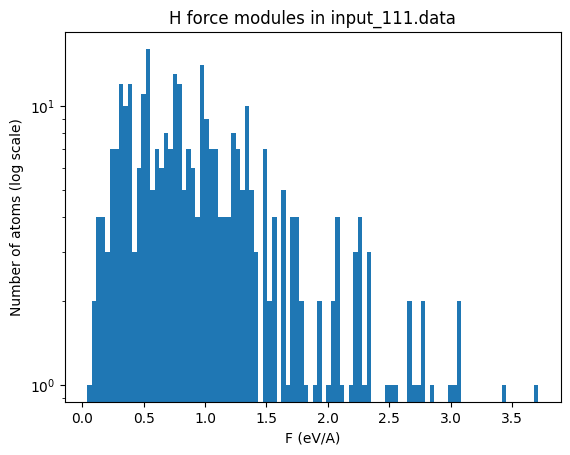

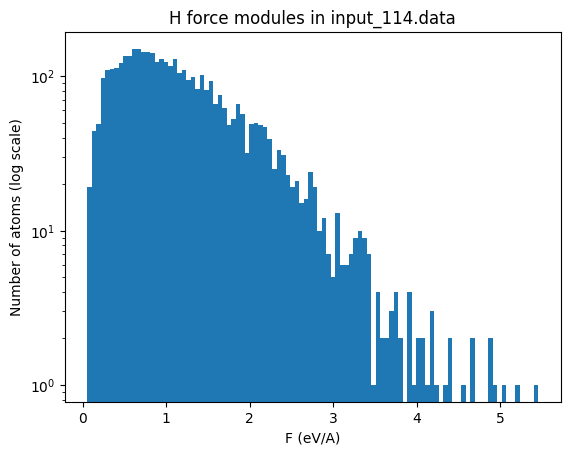

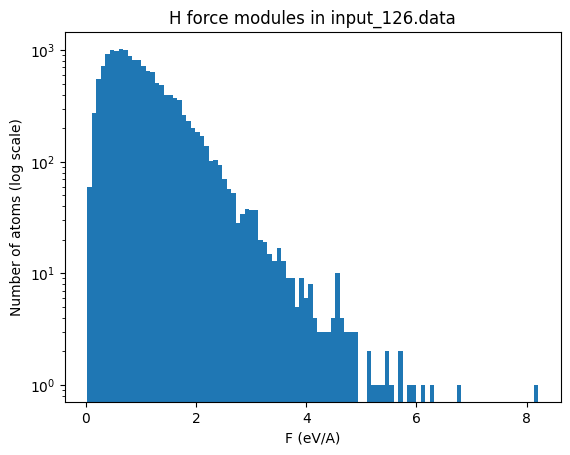

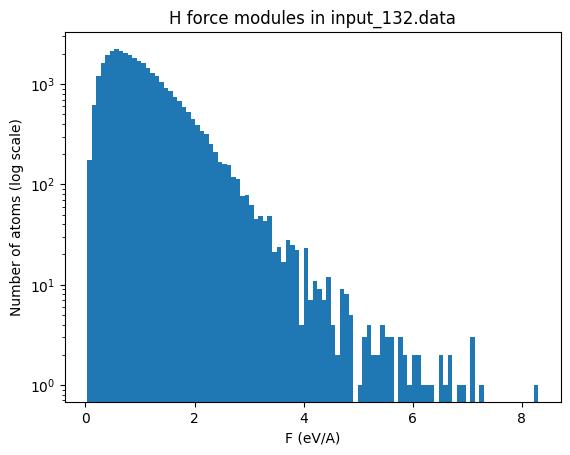

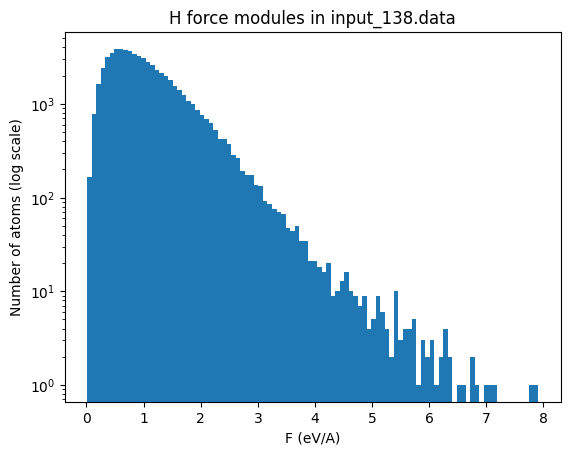

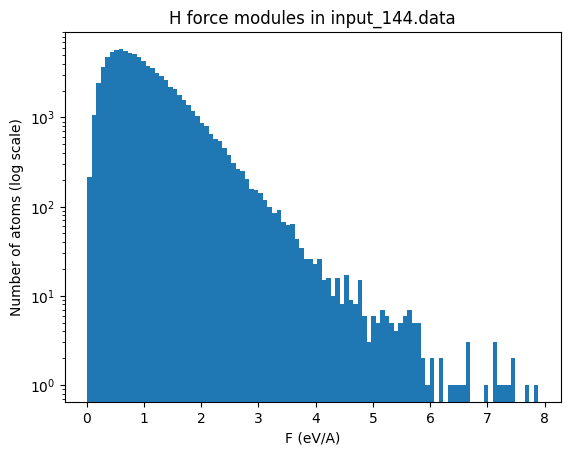

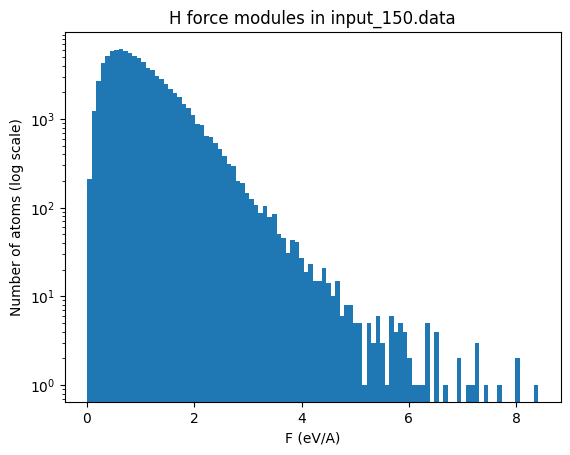

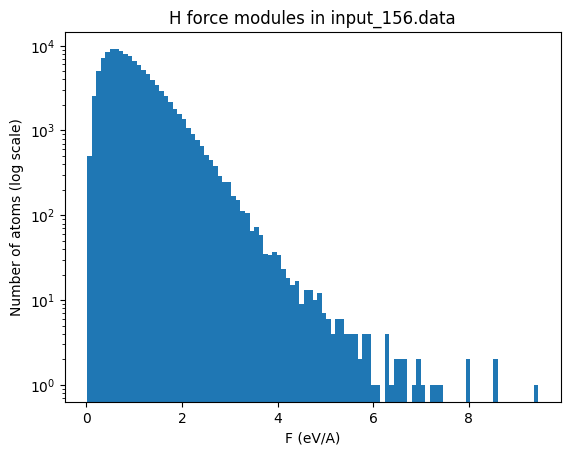

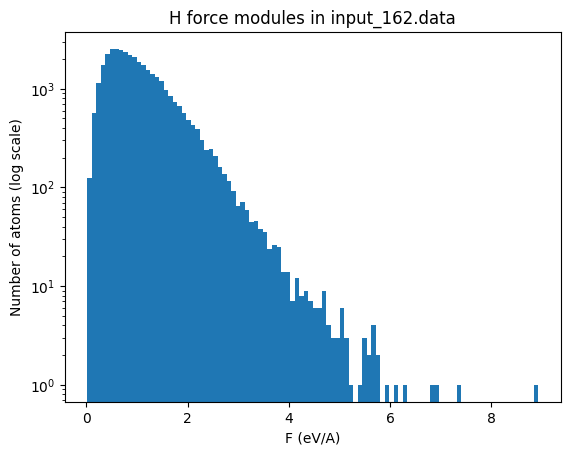

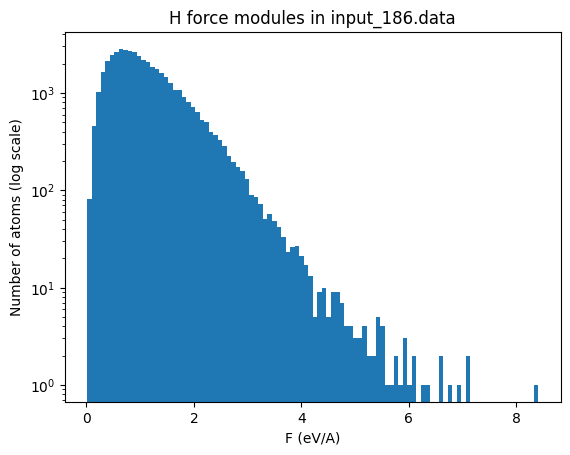

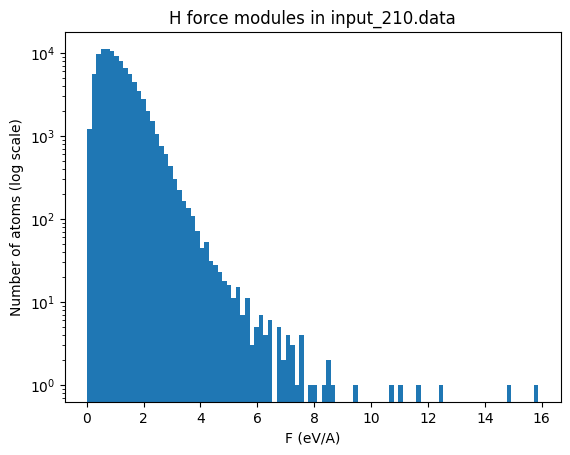

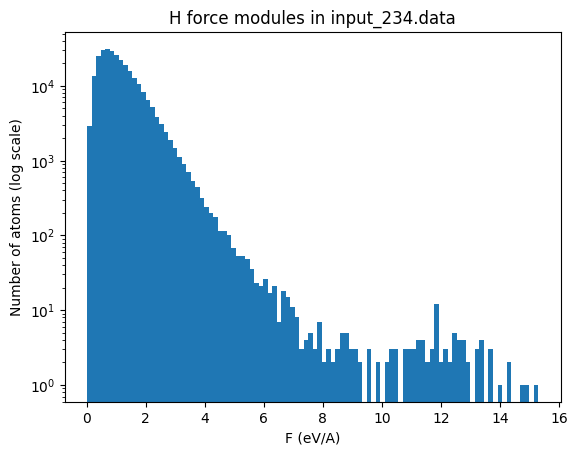

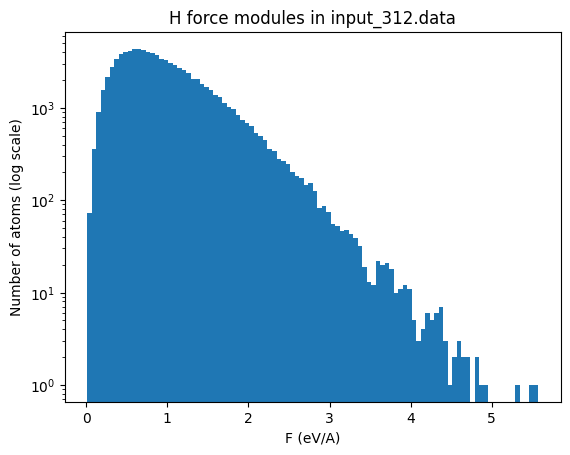

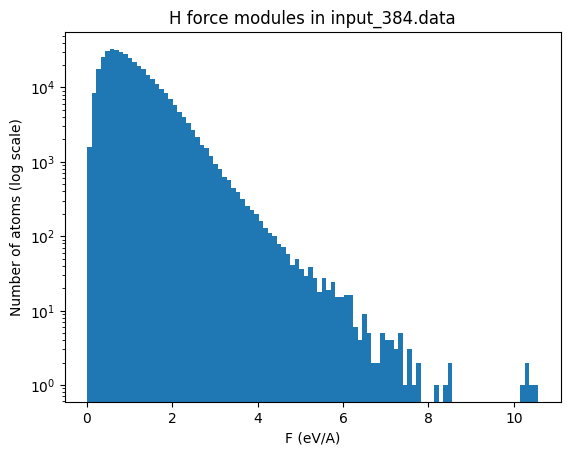

In [6]:
for i, data in enumerate(data_files):
    plt.figure(i+1)
    plt.hist(n_atom_all_H[i], bins=100)
    
    plt.yscale('log')
    plt.title('H force modules in {}'.format(data))
    plt.xlabel('F (eV/A)')
    plt.ylabel('Number of atoms (log scale)')

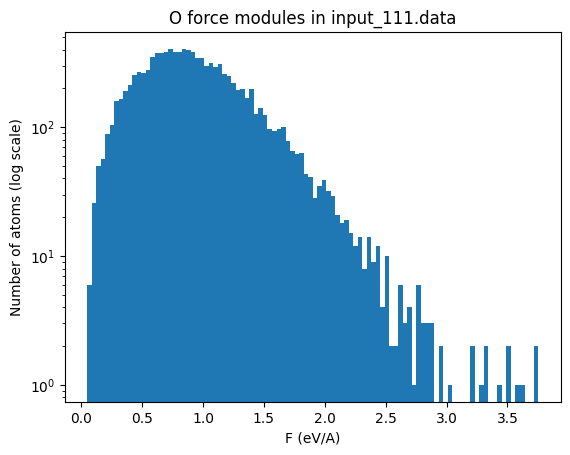

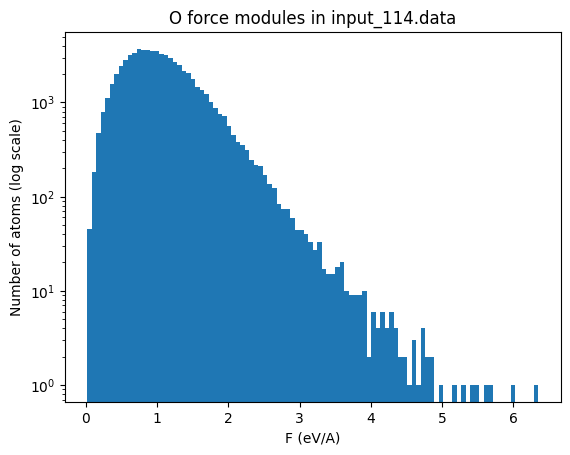

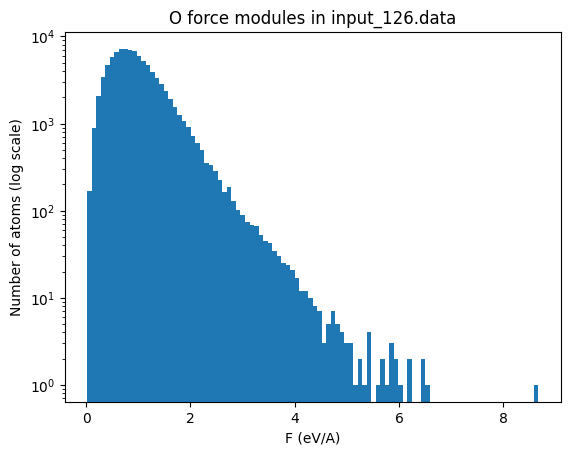

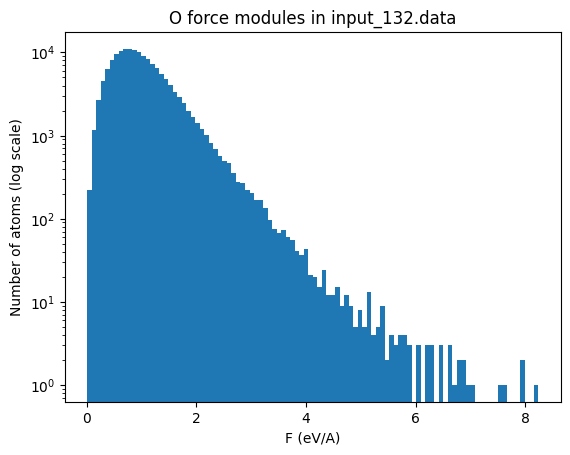

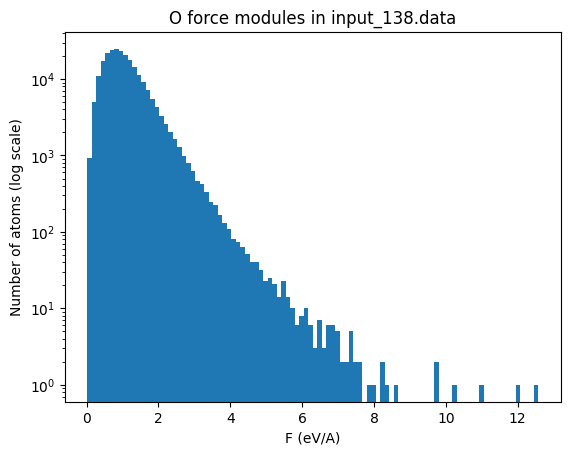

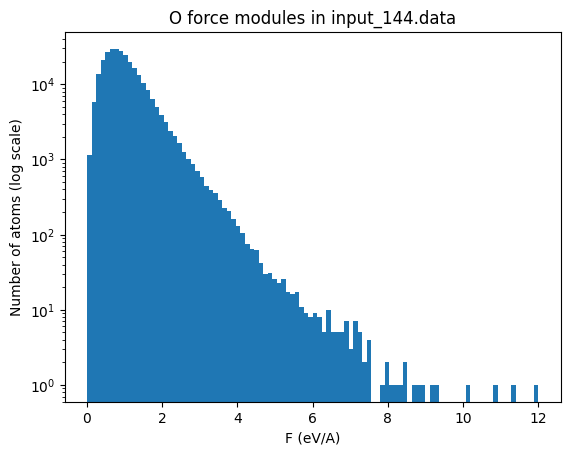

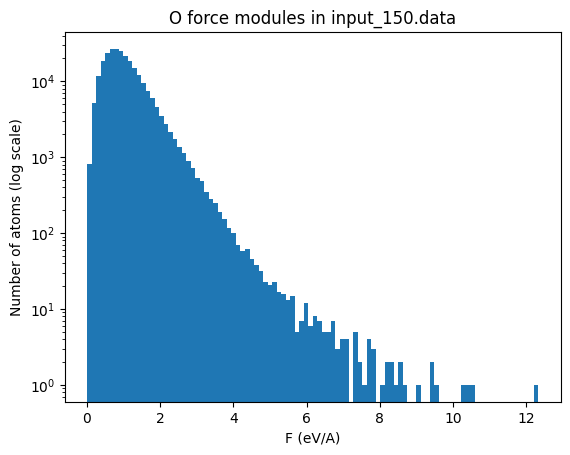

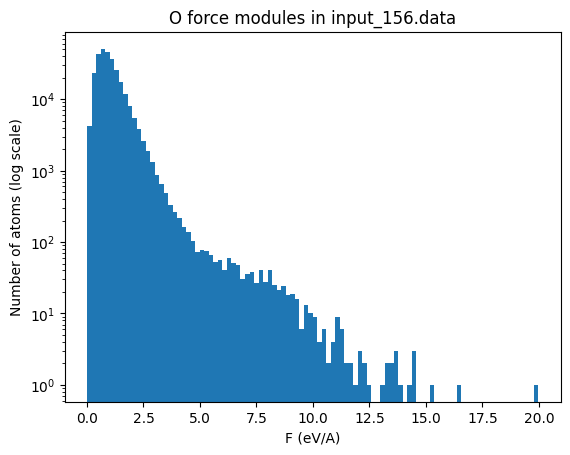

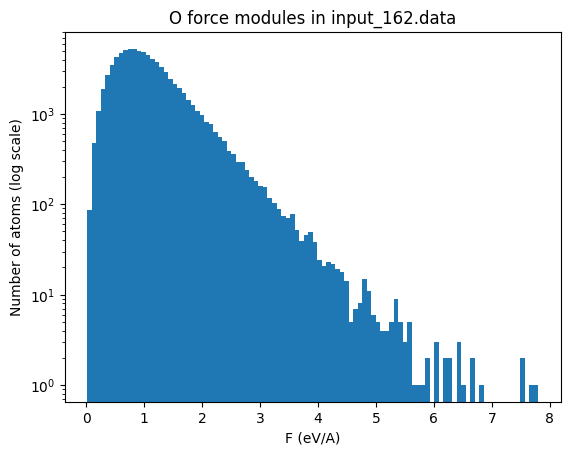

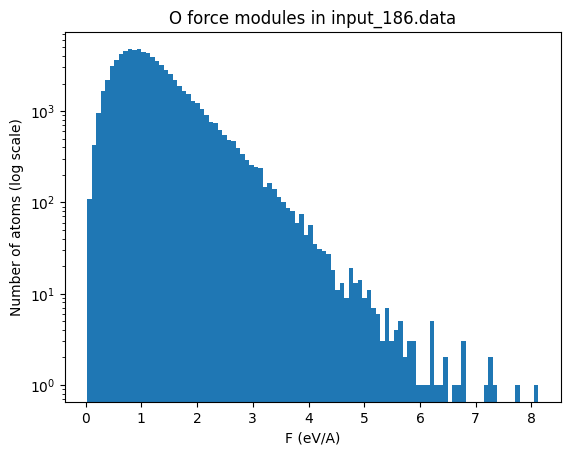

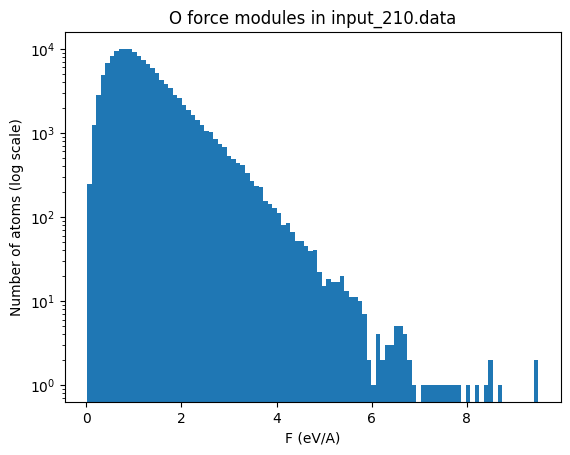

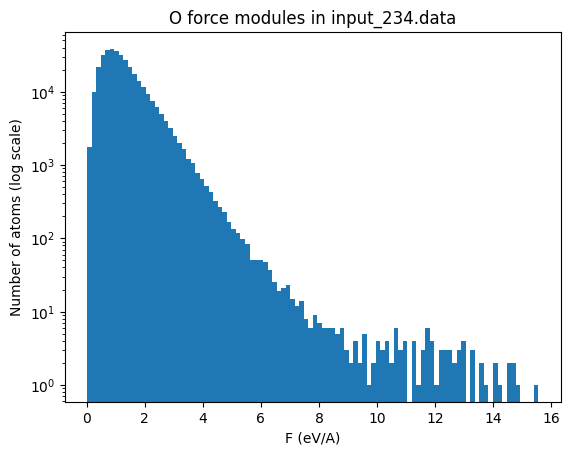

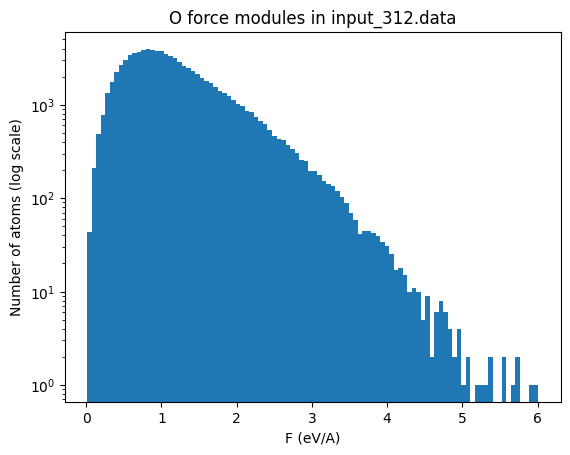

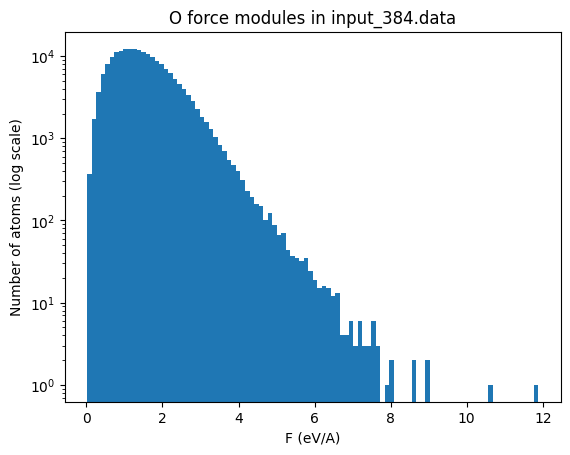

In [7]:
for i, data in enumerate(data_files):
    plt.figure(i+1)
    plt.hist(n_atom_all_O[i], bins=100)
    
    plt.yscale('log')
    plt.title('O force modules in {}'.format(data))
    plt.xlabel('F (eV/A)')
    plt.ylabel('Number of atoms (log scale)')

/tmp/ipykernel_1450372/288220836.py:5: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  plt.yscale('log')


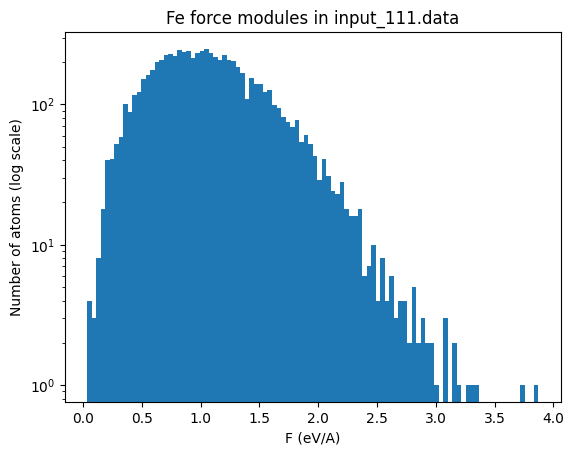

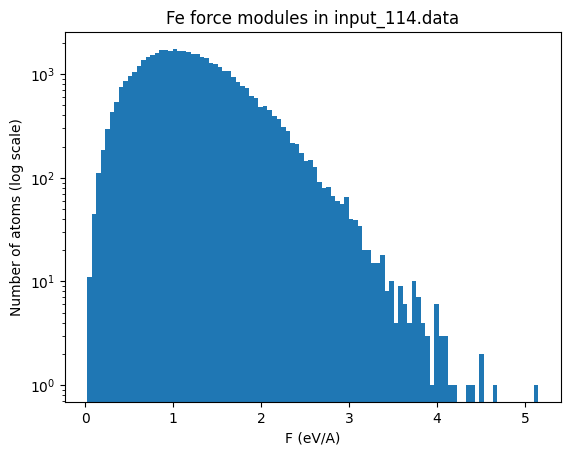

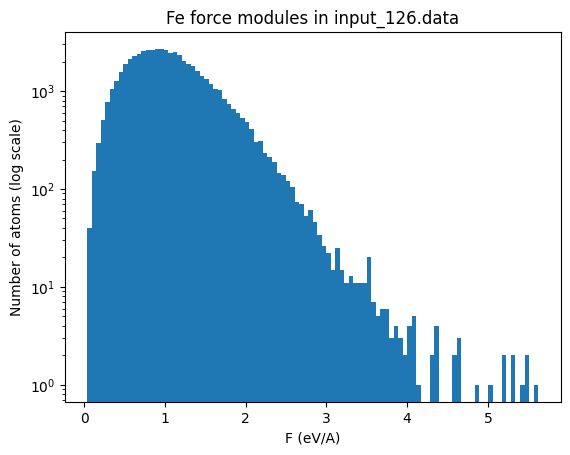

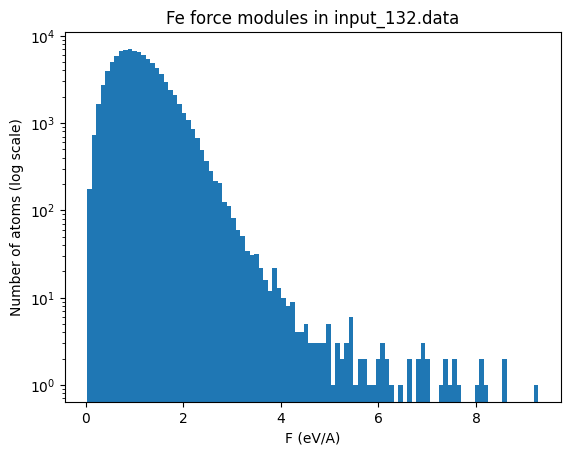

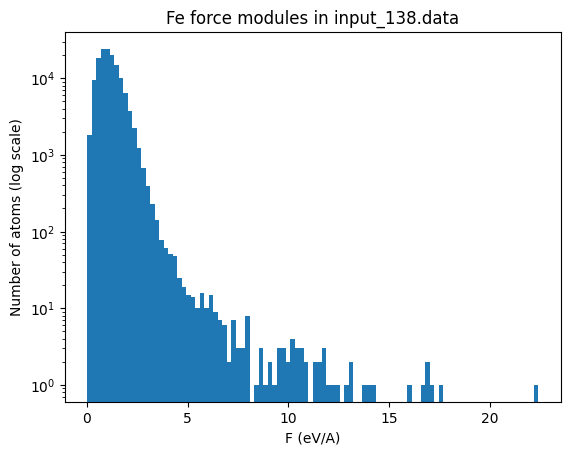

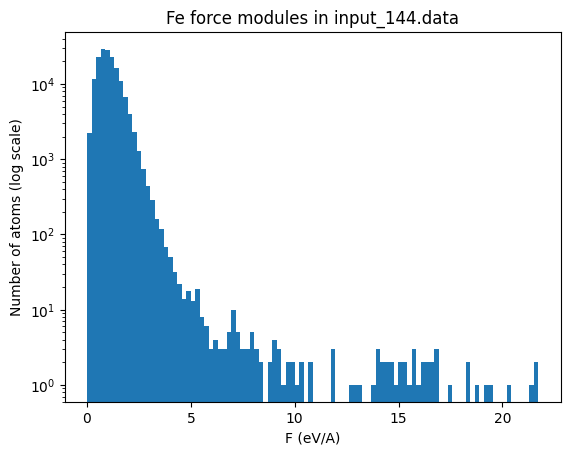

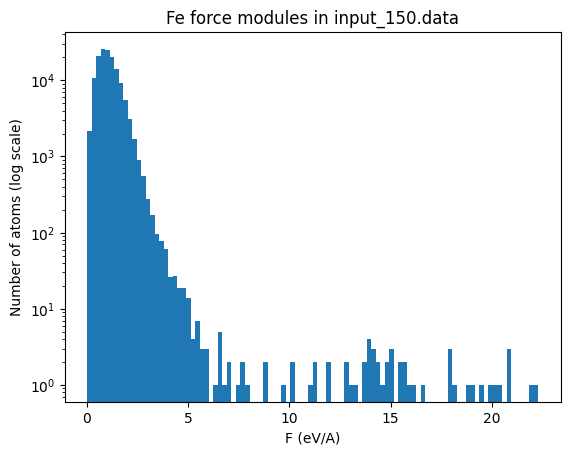

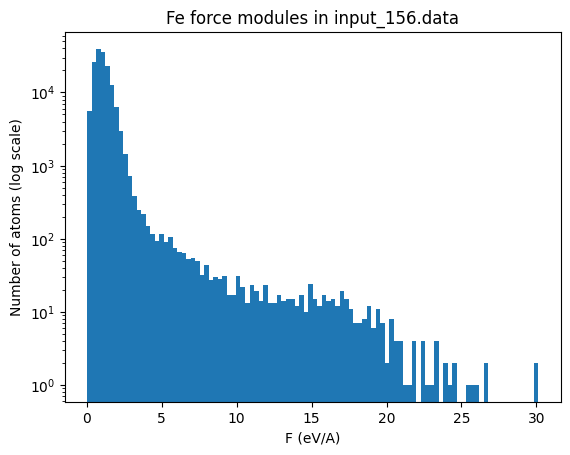

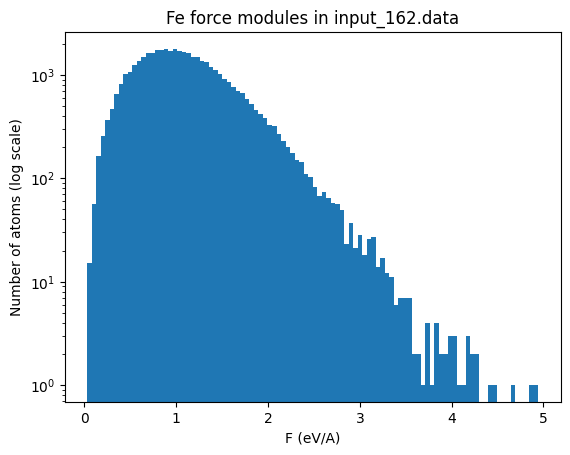

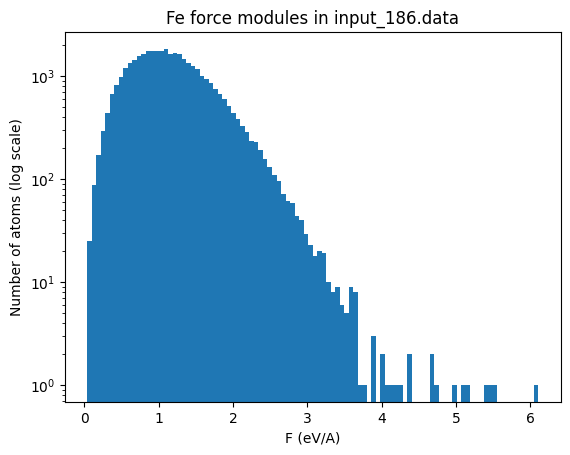

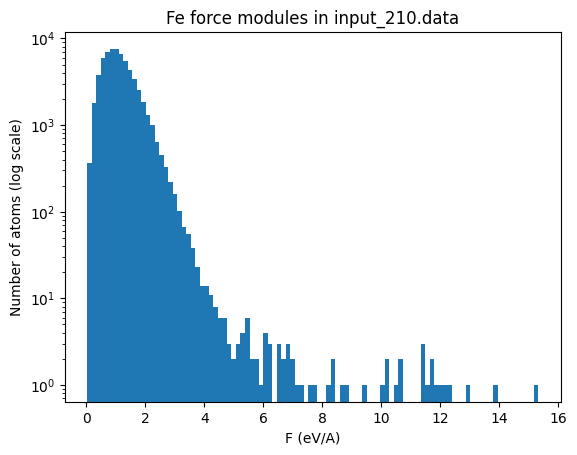

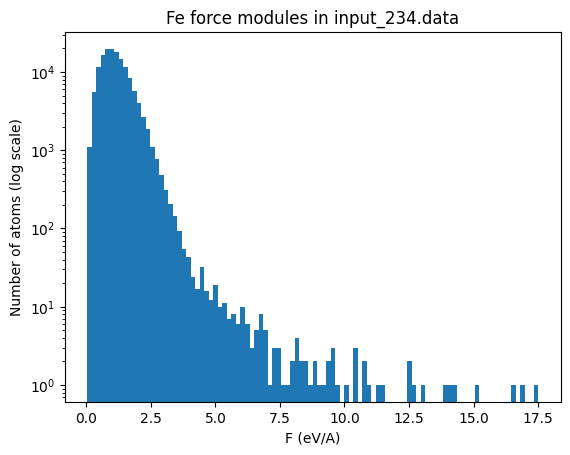

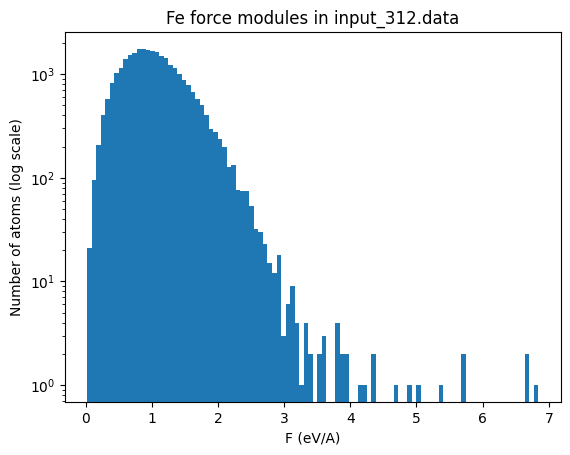

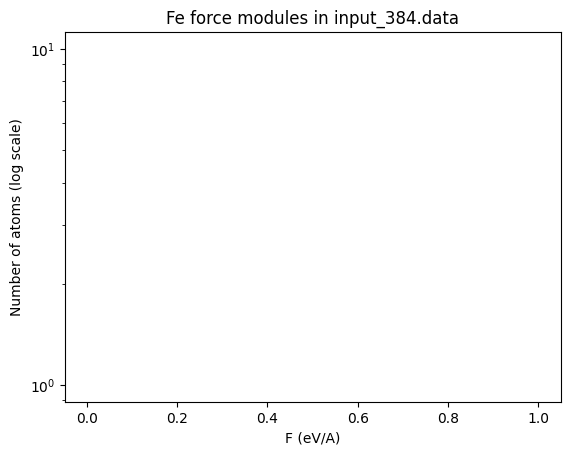

In [46]:
for i, data in enumerate(data_files):
    plt.figure(i+1)
    plt.hist(n_atom_all_Fe[i], bins=100)
    
    plt.yscale('log')
    plt.title('Fe force modules in {}'.format(data))
    plt.xlabel('F (eV/A)')
    plt.ylabel('Number of atoms (log scale)')

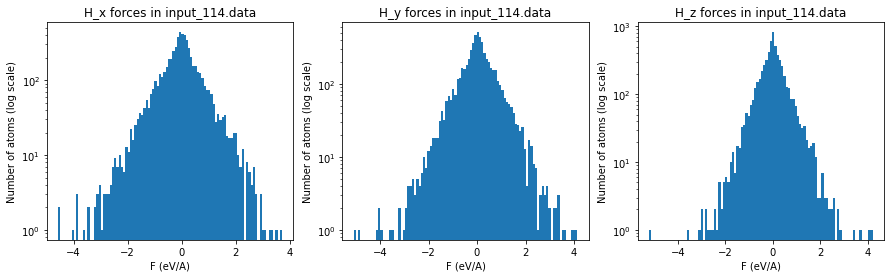

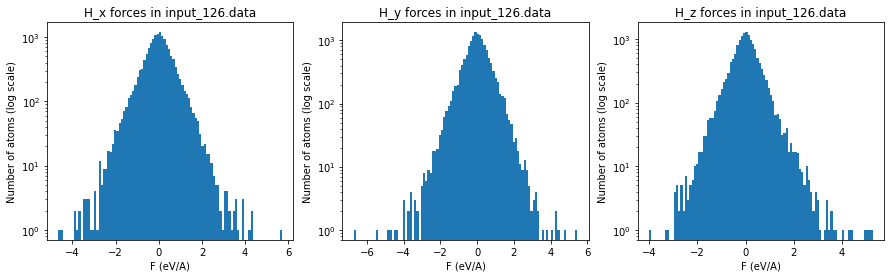

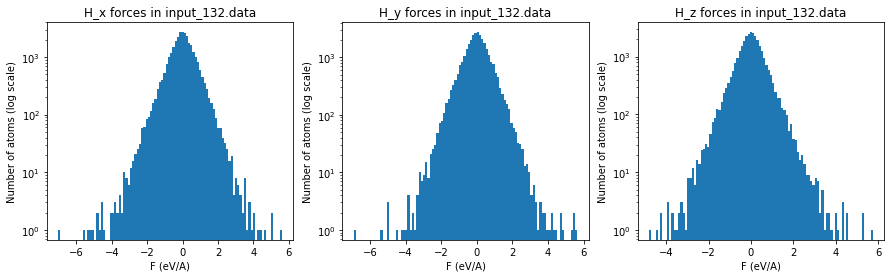

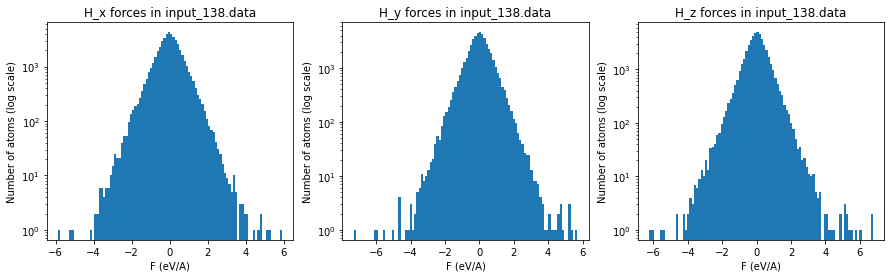

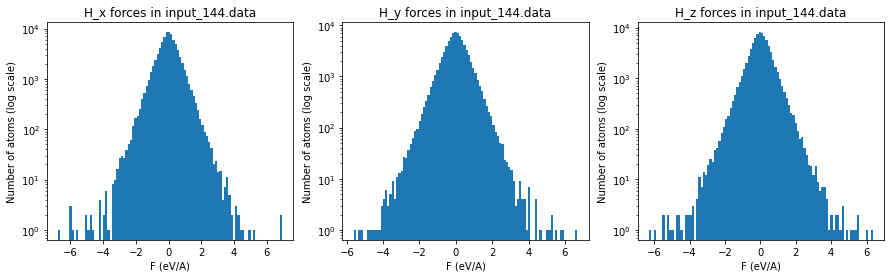

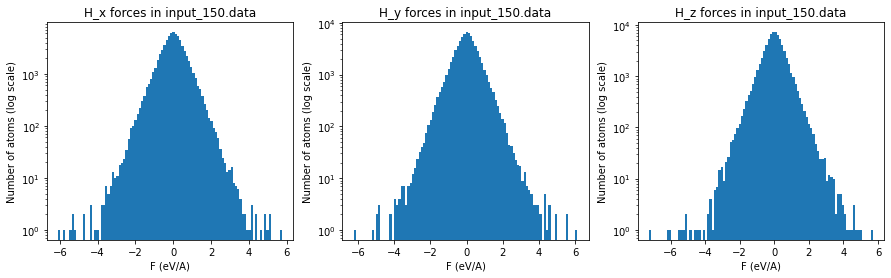

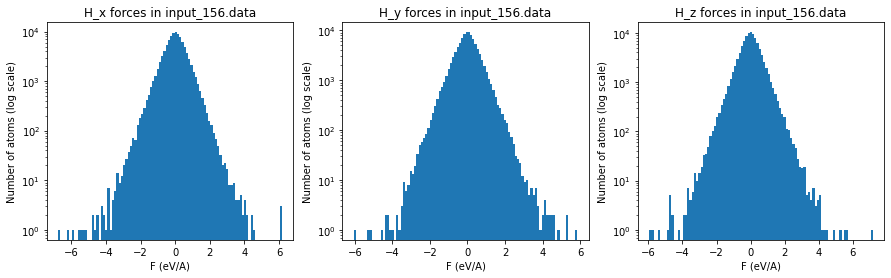

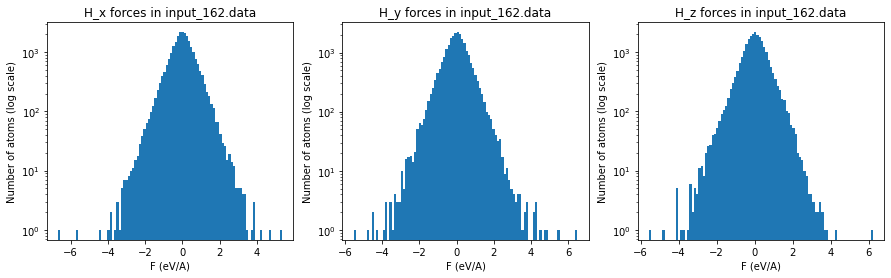

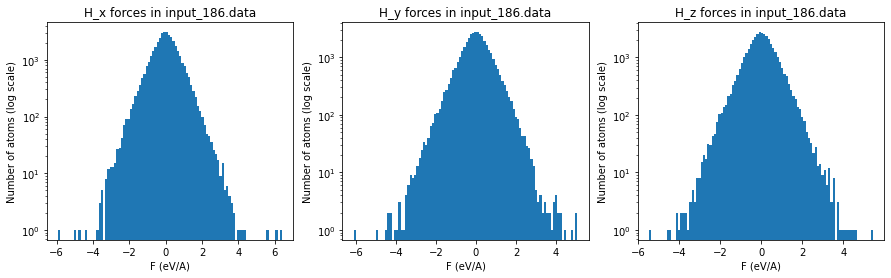

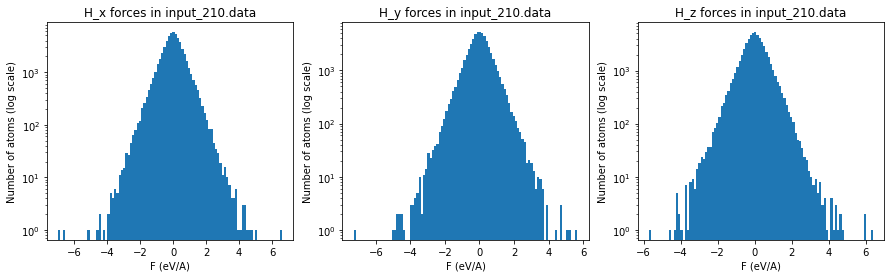

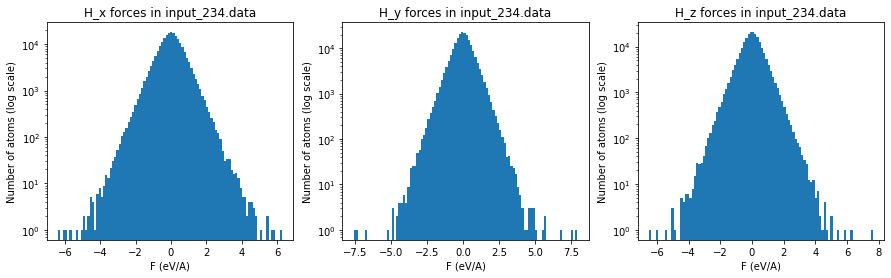

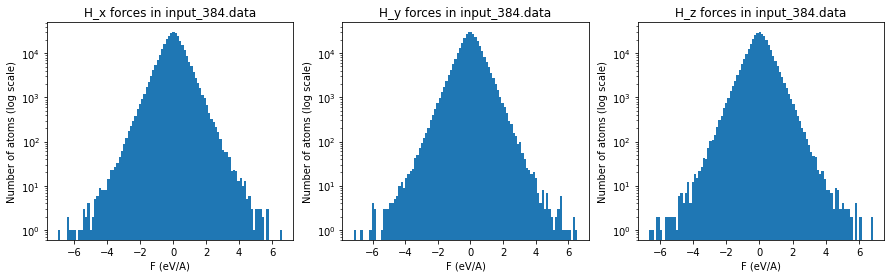

In [102]:
# Number of plots

num_plots = len(n_atom_H_v[0])
axis=[ 'x', 'y', 'z'  ]

for i, n in enumerate(data_files):
    # Set up subplots
    fig, axes = plt.subplots(1, num_plots, figsize=(15, 4))  
    # Loop through the data and plot on each subplot
    for k, ax in enumerate(axes):
        
        ax.hist(n_atom_H_v[i][k], bins=100, log=True)
    
       
        ax.set_title('H_{} forces in {}'.format(axis[k],n))
        ax.set_xlabel('F (eV/A)')
        ax.set_ylabel('Number of atoms (log scale)')
        
        

# Show the plots
plt.show()

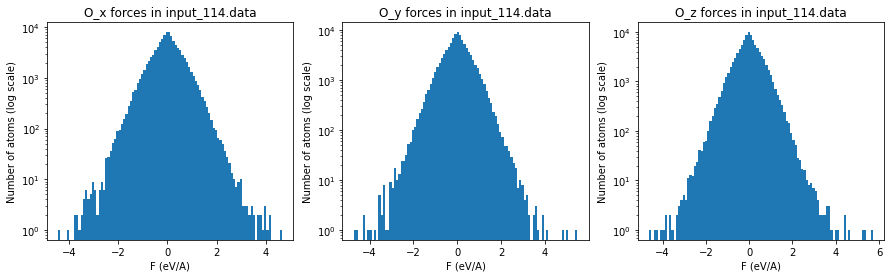

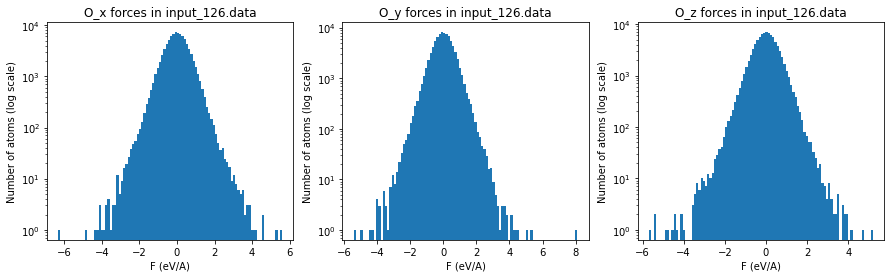

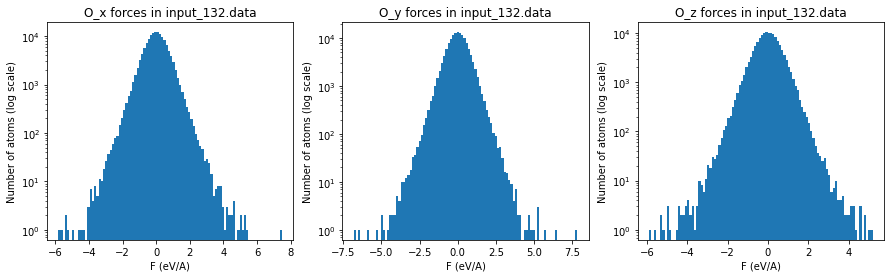

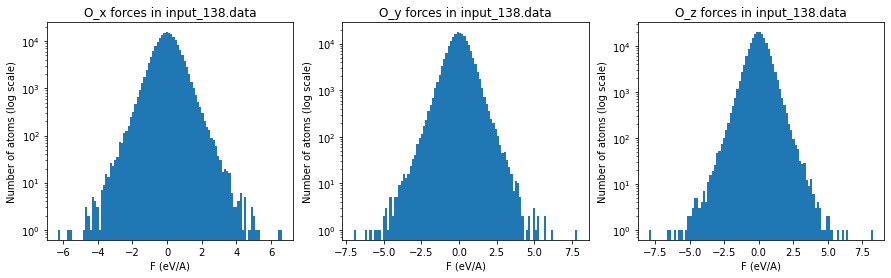

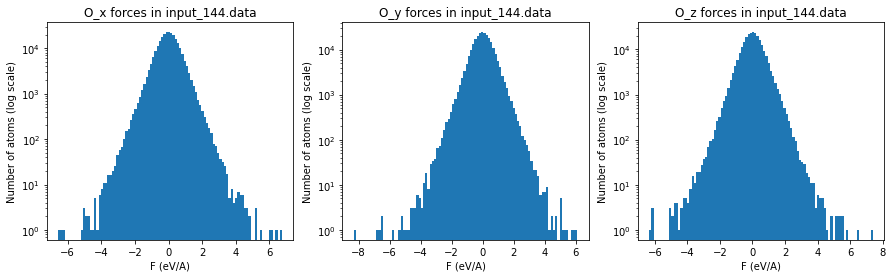

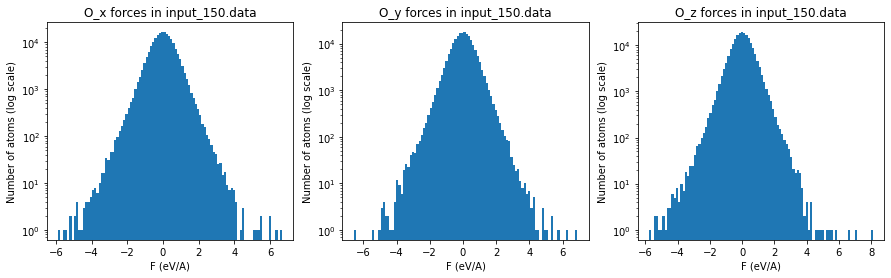

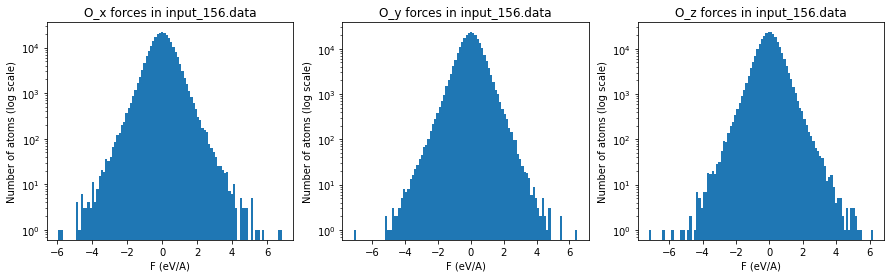

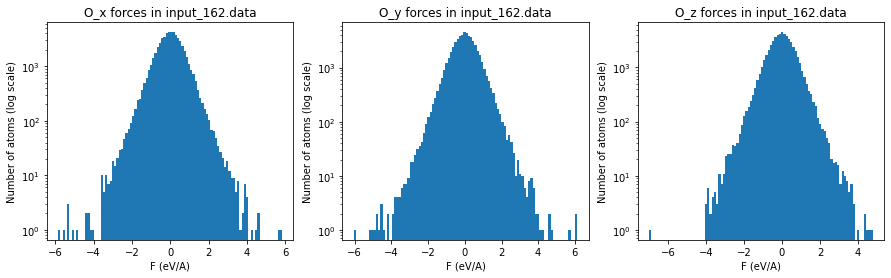

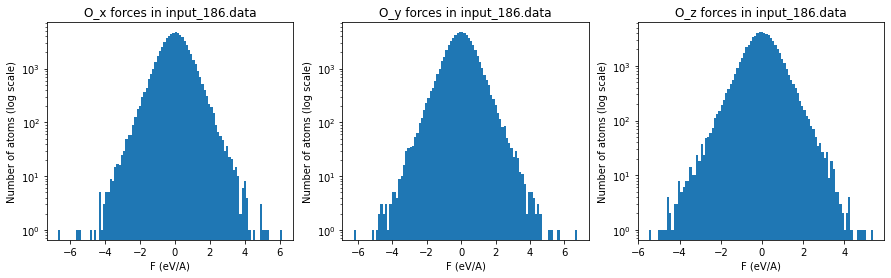

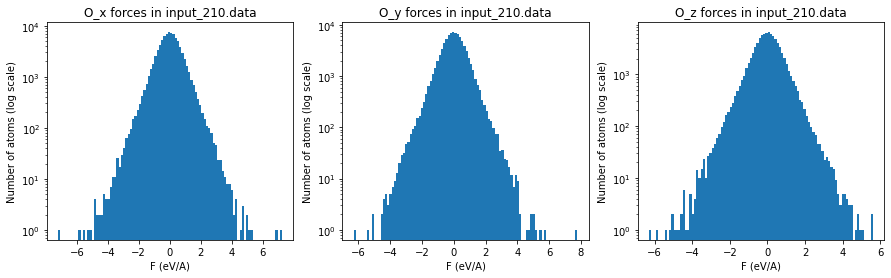

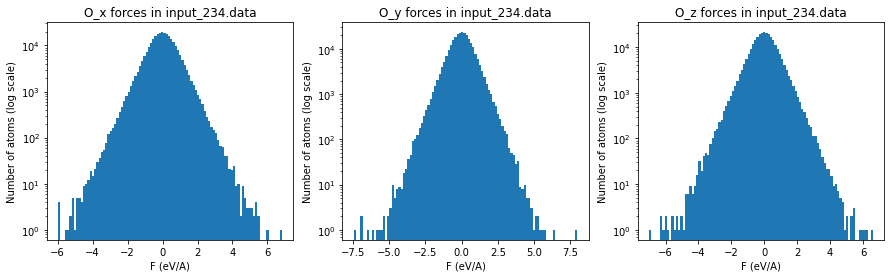

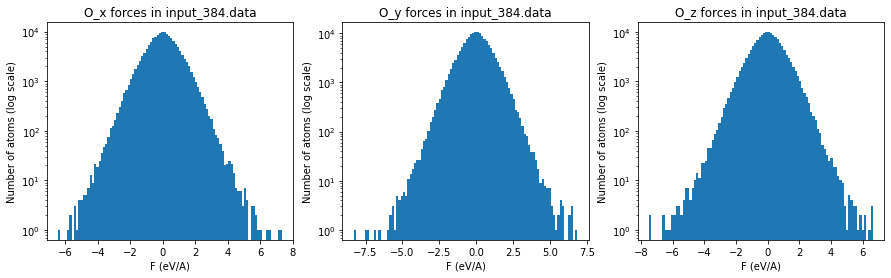

In [107]:
# Number of plots

num_plots = len(n_atom_O_v[0])
axis=[ 'x', 'y', 'z'  ]

for i, n in enumerate(data_files):
    # Set up subplots
    fig, axes = plt.subplots(1, num_plots, figsize=(15, 4))  
    # Loop through the data and plot on each subplot
    for k, ax in enumerate(axes):
        
        ax.hist(n_atom_O_v[i][k], bins=100, log=True)
    
       
        ax.set_title('O_{} forces in {}'.format(axis[k],n))
        ax.set_xlabel('F (eV/A)')
        ax.set_ylabel('Number of atoms (log scale)')
        
        

# Show the plots
plt.show()

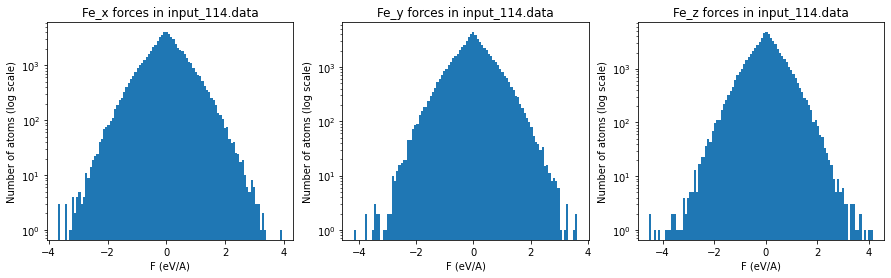

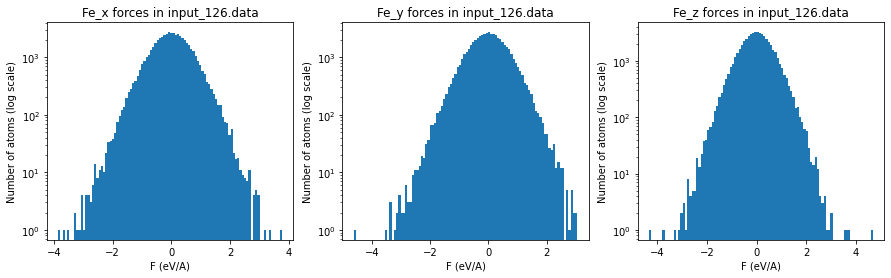

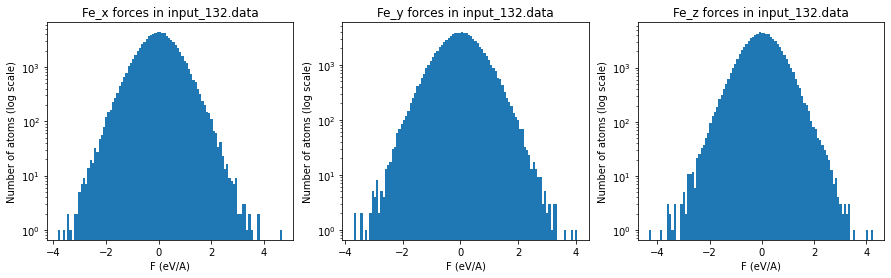

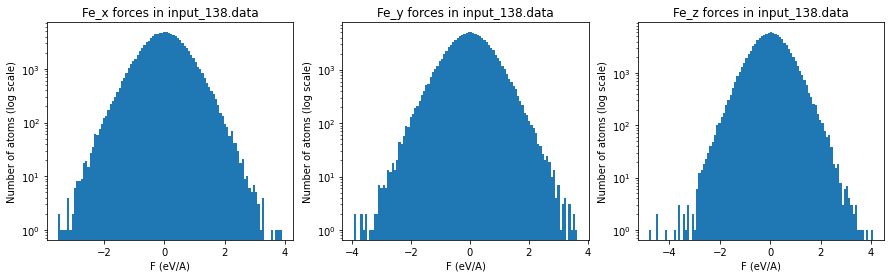

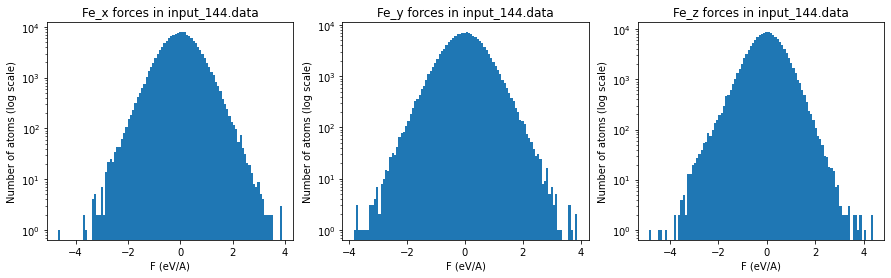

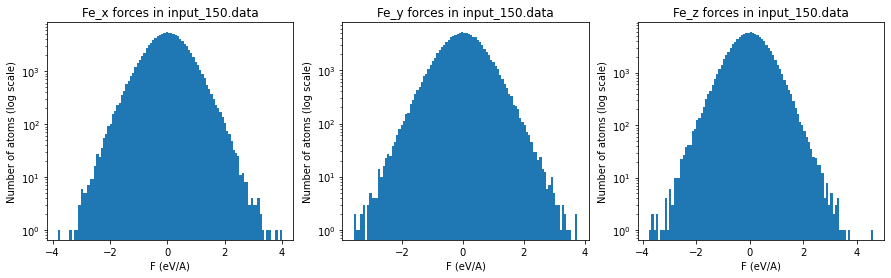

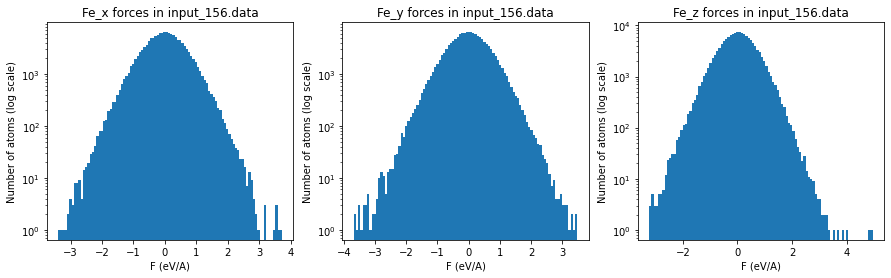

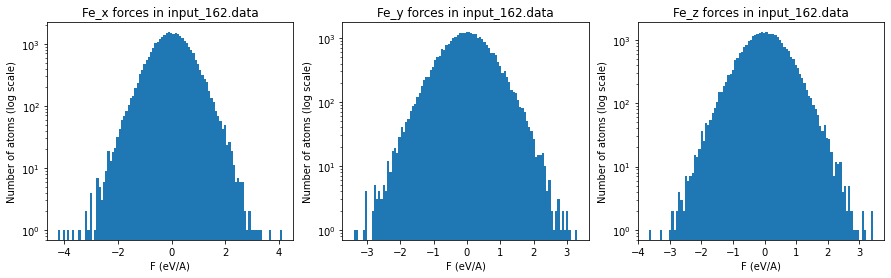

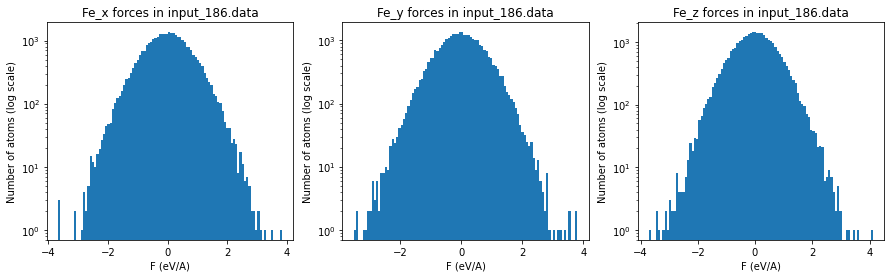

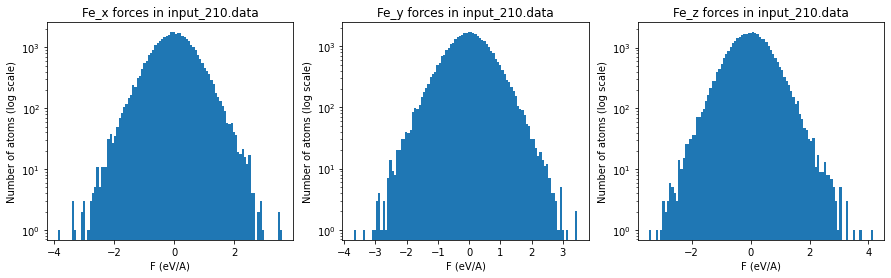

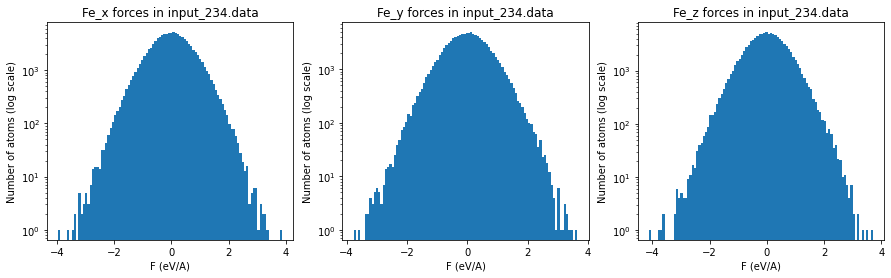

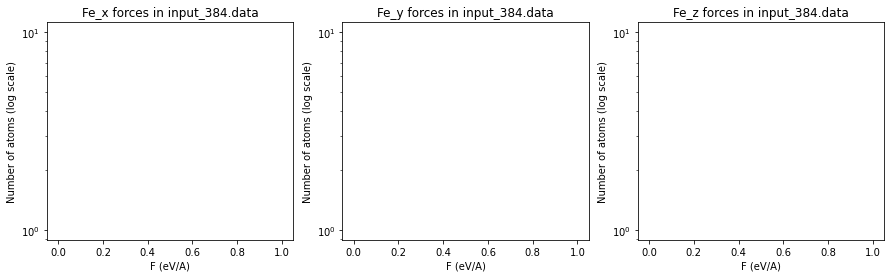

In [108]:
# Number of plots

num_plots = len(n_atom_Fe_v[0])
axis=[ 'x', 'y', 'z'  ]

for i, n in enumerate(data_files):
    # Set up subplots
    fig, axes = plt.subplots(1, num_plots, figsize=(15, 4))  
    # Loop through the data and plot on each subplot
    for k, ax in enumerate(axes):
        
        ax.hist(n_atom_Fe_v[i][k], bins=100, log=True)
    
       
        ax.set_title('Fe_{} forces in {}'.format(axis[k],n))
        ax.set_xlabel('F (eV/A)')
        ax.set_ylabel('Number of atoms (log scale)')
        
        

# Show the plots
plt.show()